## <b>Steam Games, Reviews, and Rankings Dataset Analysis</b>

### <b>Import Libraries</b>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from matplotlib.ticker import FuncFormatter, MaxNLocator
import re
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

### <b>Data Wrangling</b>

##### <b>Load Datasets</b>

In [2]:
df_games_desc = pd.read_csv('datasets/games_description.csv')
df_games_rank = pd.read_csv('datasets/games_ranking.csv')
df_games_reviews = pd.read_csv('datasets/steam_game_reviews.csv', low_memory=False)

In [3]:
df_games_desc

,name,short_description,long_description,genres,minimum_system_requirement,recommend_system_requirement,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,About This Game\n\t\t\t\t\t\t\tBlack Myth: Wuk...,"['Mythology', 'Action RPG', 'Action', 'RPG', '...",['Requires a 64-bit processor and operating sy...,['Requires a 64-bit processor and operating sy...,"19 Aug, 2024",['Game Science'],['Game Science'],Overwhelmingly Positive,"(654,820)","51,931",https://store.steampowered.com/app/2358720/Bla...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...",About This Game\n\t\t\t\t\t\t\tFor over two de...,"['FPS', 'Shooter', 'Multiplayer', 'Competitive...","['OS: Windows® 10', 'Processor: 4 hardware CPU...","['OS: Windows® 10', 'Processor: 4 hardware CPU...","21 Aug, 2012",['Valve'],['Valve'],Very Positive,"(8,313,603)","2,258,990",https://store.steampowered.com/app/730/Counter...
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...,About This Game\nEmbody the superhuman skill a...,"['Warhammer 40K', 'Action', 'Third-Person Shoo...",['Requires a 64-bit processor and operating sy...,['Requires a 64-bit processor and operating sy...,"9 Sep, 2024",['Saber Interactive'],['Focus Entertainment'],Very Positive,"(81% of 62,791) All Time","51,920",https://store.steampowered.com/app/2183900/War...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent...",About This Game\nCyberpunk 2077 is an open-wor...,"['Cyberpunk', 'Open World', 'Nudity', 'RPG', '...",['Requires a 64-bit processor and operating sy...,['Requires a 64-bit processor and operating sy...,"10 Dec, 2020",['CD PROJEKT RED'],['CD PROJEKT RED'],Very Positive,"(680,264)","324,124",https://store.steampowered.com/app/1091500/Cyb...
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...,About This Game\nTHE CRITICALLY ACCLAIMED FANT...,"['Souls-like', 'Dark Fantasy', 'Open World', '...",['Requires a 64-bit processor and operating sy...,['Requires a 64-bit processor and operating sy...,"25 Feb, 2022","['FromSoftware, Inc.']","['FromSoftware, Inc.', 'Bandai Namco Entertain...",Very Positive,"(705,261)","491,741",https://store.steampowered.com/app/1245620/ELD...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
285,MXGP PRO,Adjust your bike's configuration like a mechan...,About This Game\n\t\t\t\t\t\t\tThe official vi...,"['Simulation', 'Racing', 'Sports', 'Motocross'...",['Requires a 64-bit processor and operating sy...,['Requires a 64-bit processor and operating sy...,"29 Jun, 2018",['Milestone S.r.l.'],['Milestone S.r.l.'],Very Positive,(777),433,https://store.steampowered.com/app/798290/MXGP...
286,MXGP 2019 - The Official Motocross Videogame,Experience the excitement of the 2019 season f...,About This Game\n\t\t\t\t\t\t\tThe official Mo...,"['Simulation', 'Racing', 'Sports', 'Motorbike'...",['Requires a 64-bit processor and operating sy...,['Requires a 64-bit processor and operating sy...,"27 Aug, 2019",['Milestone S.r.l.'],['Milestone S.r.l.'],Very Positive,(90% of 858) All Time,446,https://store.steampowered.com/app/1018160/MXG...
287,Ride 2,The fastest and most iconic bikes in the world...,About This Game\n\t\t\t\t\t\t\tWelcome to the ...,"['Racing', 'Sports', 'Simulation', 'Motorbike'...",['OS *: Windows® 7 SP1 / Windows® 8 / Windows®...,['OS *: Windows® 7 SP1 64-Bit / Windows® 8 64-...,"7 Oct, 2016",['Milestone S.r.l.'],['Milestone S.r.l.'],Very Positive,"(86% of 2,335) All Time","1,045",https://store.steampowered.com/app/477770/Ride...
288,Tanuki Sunset,Master the longboard as you drift through stun...,About This Game\nGrab Your Longboard and Race ...,"['Racing', 'Action', 'Indie', 'Sports', 'Adven...","['OS *: Windows 7 (32-bit)', 'Processor: Dual ...","['OS *: Windows 7 (32-bit)', 'Processor: Dual ...","4 Dec, 2020",['Rewind Games'],['Rewind Games'],Very Posit

In [4]:
df_games_rank

,game_name,genre,rank_type,rank
0,Counter-Strike 2,Action,Sales,1
1,"Warhammer 40,000: Space Marine 2",Action,Sales,2
2,Cyberpunk 2077,Action,Sales,3
3,Black Myth: Wukong,Action,Sales,4
4,ELDEN RING,Action,Sales,5
...,...,...,...,...
667,MXGP PRO,Sports & Racing,Review,36
668,MXGP 2019 - The Official Motocross Videogame,Sports & Racing,Review,37
669,Ride 2,Sports & Racing,Review,38
670,Tanuki Sunset,Sports & Racing,Review,39


In [5]:
df_games_reviews

,review,hours_played,helpful,funny,recommendation,date,game_name,username
0,The game itself is also super fun. The PvP and...,39.9,"1,152",13,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Sentinowl\n224 products in account
1,Never cared much about Warhammer until this ga...,91.5,712,116,Recommended,13 September,"Warhammer 40,000: Space Marine 2",userpig\n248 products in account
2,A salute to all the fallen battle brothers who...,43.3,492,33,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Imparat0r\n112 products in account
3,this game feels like it was made in the mid 20...,16.8,661,15,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Fattest_falcon
4,Reminds me of something I've lost. A genuine g...,24.0,557,4,Recommended,12 September,"Warhammer 40,000: Space Marine 2",Jek\n410 products in account
...,...,...,...,...,...,...,...,...
992148,2022 Early Access Review Loads of fun!Initiall...,4.2,1,0,Recommended,"August 4, 2022",Turbo Golf Racing,"Fatal Exit\n1,902 products in account"
992149,2022 Early Access Review Great fun!,8.5,1,0,Recommended,"August 4, 2022",Turbo Golf Racing,cleybaR
992150,2022 Early Access Review Excellent pick up and...,83.3,2,0,Recommended,"August 4, 2022",Turbo Golf Racing,Sim\n600 products in account
992151,2022 Early Access Review This game is so much ...,3.8,1,0,Recommended,"August 4, 2022",Turbo Golf Racing,Fatboybadboy


##### <b>Check Dataset Info</b> 

In [6]:
df_games_desc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 13 columns):
 #   Column                                   Non-Null Count  Dtype 
---  ------                                   --------------  ----- 
 0   name                                     290 non-null    object
 1   short_description                        277 non-null    object
 2   long_description                         290 non-null    object
 3   genres                                   290 non-null    object
 4   minimum_system_requirement               290 non-null    object
 5   recommend_system_requirement             290 non-null    object
 6   release_date                             290 non-null    object
 7   developer                                290 non-null    object
 8   publisher                                290 non-null    object
 9   overall_player_rating                    290 non-null    object
 10  number_of_reviews_from_purchased_people  290 non-null    objec

In [7]:
df_games_rank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 672 entries, 0 to 671
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   game_name  672 non-null    object
 1   genre      672 non-null    object
 2   rank_type  672 non-null    object
 3   rank       672 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 21.1+ KB


In [8]:
df_games_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 992153 entries, 0 to 992152
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   review          991650 non-null  object
 1   hours_played    992153 non-null  object
 2   helpful         992153 non-null  object
 3   funny           992153 non-null  object
 4   recommendation  992153 non-null  object
 5   date            992153 non-null  object
 6   game_name       992153 non-null  object
 7   username        992072 non-null  object
dtypes: object(8)
memory usage: 60.6+ MB


##### <b>Check Statistics Parameters</b>

In [9]:
df_games_desc.describe()

,name,short_description,long_description,genres,minimum_system_requirement,recommend_system_requirement,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
count,290,277,290,290,290,290,290,290,290,290,290,290,290
unique,290,277,290,288,279,265,271,216,173,11,287,289,290
top,Grand Mountain Adventure: Wonderlands,Grand Mountain Adventure: Wonderlands lets you...,About This Game\n\t\t\t\t\t\t\tGrand Mountain ...,"['Sports', 'Simulation', 'Basketball', 'eSport...",['Requires a 64-bit processor and operating sy...,['Requires a 64-bit processor and operating sy...,"10 Sep, 2024",['Milestone S.r.l.'],['Electronic Arts'],Very Positive,() All Time,2,https://store.steampowered.com/app/1247360/Gra...
freq,1,1,1,2,4,14,3,10,15,146,4,2,1


In [10]:
df_games_rank.describe()

,rank
count,672.000000
mean,19.857143
std,11.509232
min,1.000000
25%,10.000000
50%,20.000000
75%,30.000000
max,40.000000


In [11]:
df_games_reviews.describe()

,review,hours_played,helpful,funny,recommendation,date,game_name,username
count,991650,992153,992153,992153,992153,992153,992153,992072
unique,909736,44229,2641,1733,2,6147,242,765581
top,good,0.2,1,0,Recommended,"November 22, 2023",Tom Clancy's Rainbow Six® Siege,123
freq,1111,3305,256331,744249,805782,3048,5010,161


##### <b>Check Missing Values</b>

In [12]:
df_games_desc.isna().sum()

name                                        0
short_description                          13
long_description                            0
genres                                      0
minimum_system_requirement                  0
recommend_system_requirement                0
release_date                                0
developer                                   0
publisher                                   0
overall_player_rating                       0
number_of_reviews_from_purchased_people     0
number_of_english_reviews                   0
link                                        0
dtype: int64

In [13]:
df_games_rank.isna().sum()

game_name    0
genre        0
rank_type    0
rank         0
dtype: int64

In [14]:
df_games_reviews.isna().sum()

review            503
hours_played        0
helpful             0
funny               0
recommendation      0
date                0
game_name           0
username           81
dtype: int64

##### <b>Check Duplicates</b>

In [15]:
df_games_desc_dupes = df_games_desc.duplicated().value_counts()
df_games_desc_dupes

False    290
Name: count, dtype: int64

In [16]:
df_games_rank_dupes = df_games_rank.duplicated().value_counts()
df_games_rank_dupes

False    672
Name: count, dtype: int64

In [17]:
df_games_reviews_dupes = df_games_reviews.duplicated().value_counts()
df_games_reviews_dupes

False    992152
True          1
Name: count, dtype: int64

### <b>Data Cleaning</b>

In [18]:
# Create a copy of each dataframe
df_games_desc_clean = df_games_desc.copy()
df_games_rank_clean = df_games_rank.copy()
df_games_reviews_clean = df_games_reviews.copy()

#### <b>Clean df_games_desc_clean</b>

##### <b>Drop unnecessary columns</b>

In [19]:
columns_to_drop = [
    'minimum_system_requirement',	
    'recommend_system_requirement'
]

df_games_desc_clean = df_games_desc_clean.drop(columns=columns_to_drop)
df_games_desc_clean.head()

,name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,About This Game\n\t\t\t\t\t\t\tBlack Myth: Wuk...,"['Mythology', 'Action RPG', 'Action', 'RPG', '...","19 Aug, 2024",['Game Science'],['Game Science'],Overwhelmingly Positive,"(654,820)","51,931",https://store.steampowered.com/app/2358720/Bla...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...",About This Game\n\t\t\t\t\t\t\tFor over two de...,"['FPS', 'Shooter', 'Multiplayer', 'Competitive...","21 Aug, 2012",['Valve'],['Valve'],Very Positive,"(8,313,603)","2,258,990",https://store.steampowered.com/app/730/Counter...
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...,About This Game\nEmbody the superhuman skill a...,"['Warhammer 40K', 'Action', 'Third-Person Shoo...","9 Sep, 2024",['Saber Interactive'],['Focus Entertainment'],Very Positive,"(81% of 62,791) All Time","51,920",https://store.steampowered.com/app/2183900/War...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent...",About This Game\nCyberpunk 2077 is an open-wor...,"['Cyberpunk', 'Open World', 'Nudity', 'RPG', '...","10 Dec, 2020",['CD PROJEKT RED'],['CD PROJEKT RED'],Very Positive,"(680,264)","324,124",https://store.steampowered.com/app/1091500/Cyb...
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...,About This Game\nTHE CRITICALLY ACCLAIMED FANT...,"['Souls-like', 'Dark Fantasy', 'Open World', '...","25 Feb, 2022","['FromSoftware, Inc.']","['FromSoftware, Inc.', 'Bandai Namco Entertain...",Very Positive,"(705,261)","491,741",https://store.steampowered.com/app/1245620/ELD...


##### <b>Rename columns</b>

In [20]:
df_games_desc_clean = df_games_desc_clean.rename(columns={
    'name': 'game_name',
})
df_games_desc_clean.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,About This Game\n\t\t\t\t\t\t\tBlack Myth: Wuk...,"['Mythology', 'Action RPG', 'Action', 'RPG', '...","19 Aug, 2024",['Game Science'],['Game Science'],Overwhelmingly Positive,"(654,820)","51,931",https://store.steampowered.com/app/2358720/Bla...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...",About This Game\n\t\t\t\t\t\t\tFor over two de...,"['FPS', 'Shooter', 'Multiplayer', 'Competitive...","21 Aug, 2012",['Valve'],['Valve'],Very Positive,"(8,313,603)","2,258,990",https://store.steampowered.com/app/730/Counter...
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...,About This Game\nEmbody the superhuman skill a...,"['Warhammer 40K', 'Action', 'Third-Person Shoo...","9 Sep, 2024",['Saber Interactive'],['Focus Entertainment'],Very Positive,"(81% of 62,791) All Time","51,920",https://store.steampowered.com/app/2183900/War...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent...",About This Game\nCyberpunk 2077 is an open-wor...,"['Cyberpunk', 'Open World', 'Nudity', 'RPG', '...","10 Dec, 2020",['CD PROJEKT RED'],['CD PROJEKT RED'],Very Positive,"(680,264)","324,124",https://store.steampowered.com/app/1091500/Cyb...
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...,About This Game\nTHE CRITICALLY ACCLAIMED FANT...,"['Souls-like', 'Dark Fantasy', 'Open World', '...","25 Feb, 2022","['FromSoftware, Inc.']","['FromSoftware, Inc.', 'Bandai Namco Entertain...",Very Positive,"(705,261)","491,741",https://store.steampowered.com/app/1245620/ELD...


##### <b>Fill missing values with a placeholder</b>

In [21]:
df_games_desc_clean['short_description'] = df_games_desc_clean['short_description'].fillna('There is no short description')

df_games_desc_clean.isna().sum()

game_name                                  0
short_description                          0
long_description                           0
genres                                     0
release_date                               0
developer                                  0
publisher                                  0
overall_player_rating                      0
number_of_reviews_from_purchased_people    0
number_of_english_reviews                  0
link                                       0
dtype: int64

##### <b>Remove 'About This Game' prefix from long_description</b>

In [22]:
df_games_desc_clean['long_description'] = df_games_desc_clean['long_description'].str.replace(r'^About This Game[\n\t\s]*', '', regex=True)

##### <b>Extract number of reviews using regex</b>

In [23]:
num_of_reviews_regex = r"\b\d{1,3}(?:,\d{3})+\b|\b\d+\b(?!%)"
df_games_desc_clean['number_of_reviews_from_purchased_people'] = df_games_desc_clean['number_of_reviews_from_purchased_people'].str.findall(num_of_reviews_regex).str[0]

df_games_desc_clean.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,"['Mythology', 'Action RPG', 'Action', 'RPG', '...","19 Aug, 2024",['Game Science'],['Game Science'],Overwhelmingly Positive,"654,820","51,931",https://store.steampowered.com/app/2358720/Bla...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","['FPS', 'Shooter', 'Multiplayer', 'Competitive...","21 Aug, 2012",['Valve'],['Valve'],Very Positive,"8,313,603","2,258,990",https://store.steampowered.com/app/730/Counter...
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...,Embody the superhuman skill and brutality of a...,"['Warhammer 40K', 'Action', 'Third-Person Shoo...","9 Sep, 2024",['Saber Interactive'],['Focus Entertainment'],Very Positive,"62,791","51,920",https://store.steampowered.com/app/2183900/War...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent...","Cyberpunk 2077 is an open-world, action-advent...","['Cyberpunk', 'Open World', 'Nudity', 'RPG', '...","10 Dec, 2020",['CD PROJEKT RED'],['CD PROJEKT RED'],Very Positive,"680,264","324,124",https://store.steampowered.com/app/1091500/Cyb...
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...,THE CRITICALLY ACCLAIMED FANTASY ACTION RPGRis...,"['Souls-like', 'Dark Fantasy', 'Open World', '...","25 Feb, 2022","['FromSoftware, Inc.']","['FromSoftware, Inc.', 'Bandai Namco Entertain...",Very Positive,"705,261","491,741",https://store.steampowered.com/app/1245620/ELD...


In [24]:
df_games_desc_clean = df_games_desc_clean.replace({'number_of_reviews_from_purchased_people': ',', 'number_of_english_reviews': ','}, '', regex=True)
df_games_desc_clean.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,"['Mythology', 'Action RPG', 'Action', 'RPG', '...","19 Aug, 2024",['Game Science'],['Game Science'],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","['FPS', 'Shooter', 'Multiplayer', 'Competitive...","21 Aug, 2012",['Valve'],['Valve'],Very Positive,8313603,2258990,https://store.steampowered.com/app/730/Counter...
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...,Embody the superhuman skill and brutality of a...,"['Warhammer 40K', 'Action', 'Third-Person Shoo...","9 Sep, 2024",['Saber Interactive'],['Focus Entertainment'],Very Positive,62791,51920,https://store.steampowered.com/app/2183900/War...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent...","Cyberpunk 2077 is an open-world, action-advent...","['Cyberpunk', 'Open World', 'Nudity', 'RPG', '...","10 Dec, 2020",['CD PROJEKT RED'],['CD PROJEKT RED'],Very Positive,680264,324124,https://store.steampowered.com/app/1091500/Cyb...
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...,THE CRITICALLY ACCLAIMED FANTASY ACTION RPGRis...,"['Souls-like', 'Dark Fantasy', 'Open World', '...","25 Feb, 2022","['FromSoftware, Inc.']","['FromSoftware, Inc.', 'Bandai Namco Entertain...",Very Positive,705261,491741,https://store.steampowered.com/app/1245620/ELD...


In [25]:
df_games_desc_clean = df_games_desc_clean.fillna(0)

##### <b>Parse categorical columns using ast.literal_eval</b>

In [26]:
# Categorical columns
cat_cols = [
    'genres',
    'developer',
    'publisher'
]

for cols in cat_cols:
    df_games_desc_clean[cols] = df_games_desc_clean[cols].apply(ast.literal_eval)

df_games_desc_clean.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,"[Mythology, Action RPG, Action, RPG, Souls-lik...","19 Aug, 2024",[Game Science],[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","[FPS, Shooter, Multiplayer, Competitive, Actio...","21 Aug, 2012",[Valve],[Valve],Very Positive,8313603,2258990,https://store.steampowered.com/app/730/Counter...
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...,Embody the superhuman skill and brutality of a...,"[Warhammer 40K, Action, Third-Person Shooter, ...","9 Sep, 2024",[Saber Interactive],[Focus Entertainment],Very Positive,62791,51920,https://store.steampowered.com/app/2183900/War...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent...","Cyberpunk 2077 is an open-world, action-advent...","[Cyberpunk, Open World, Nudity, RPG, Singlepla...","10 Dec, 2020",[CD PROJEKT RED],[CD PROJEKT RED],Very Positive,680264,324124,https://store.steampowered.com/app/1091500/Cyb...
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...,THE CRITICALLY ACCLAIMED FANTASY ACTION RPGRis...,"[Souls-like, Dark Fantasy, Open World, RPG, Di...","25 Feb, 2022","[FromSoftware, Inc.]","[FromSoftware, Inc., Bandai Namco Entertainment]",Very Positive,705261,491741,https://store.steampowered.com/app/1245620/ELD...


##### <b>Convert data type</b>

In [27]:
# Change release_date type do datetime
df_games_desc_clean['release_date'] = pd.to_datetime(df_games_desc_clean['release_date'], format='mixed', errors='coerce')

In [28]:
# Change numerical columns to numerical data type
num_cols = [
    'number_of_reviews_from_purchased_people',
    'number_of_english_reviews'
]

df_games_desc_clean[num_cols] = df_games_desc_clean[num_cols].apply(pd.to_numeric, errors='coerce')
df_games_desc_clean.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,"[Mythology, Action RPG, Action, RPG, Souls-lik...",2024-08-19,[Game Science],[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","[FPS, Shooter, Multiplayer, Competitive, Actio...",2012-08-21,[Valve],[Valve],Very Positive,8313603,2258990,https://store.steampowered.com/app/730/Counter...
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...,Embody the superhuman skill and brutality of a...,"[Warhammer 40K, Action, Third-Person Shooter, ...",2024-09-09,[Saber Interactive],[Focus Entertainment],Very Positive,62791,51920,https://store.steampowered.com/app/2183900/War...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent...","Cyberpunk 2077 is an open-world, action-advent...","[Cyberpunk, Open World, Nudity, RPG, Singlepla...",2020-12-10,[CD PROJEKT RED],[CD PROJEKT RED],Very Positive,680264,324124,https://store.steampowered.com/app/1091500/Cyb...
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...,THE CRITICALLY ACCLAIMED FANTASY ACTION RPGRis...,"[Souls-like, Dark Fantasy, Open World, RPG, Di...",2022-02-25,"[FromSoftware, Inc.]","[FromSoftware, Inc., Bandai Namco Entertainment]",Very Positive,705261,491741,https://store.steampowered.com/app/1245620/ELD...


##### <b>Explode game genres</b>

In [29]:
df_genres_exploded = df_games_desc_clean.explode('genres')
df_genres_exploded.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,Mythology,2024-08-19,[Game Science],[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,Action RPG,2024-08-19,[Game Science],[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,Action,2024-08-19,[Game Science],[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,RPG,2024-08-19,[Game Science],[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,Souls-like,2024-08-19,[Game Science],[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...


##### <b>Explode game developer</b>

In [30]:
df_dev_exploded = df_games_desc_clean.explode('developer')
df_dev_exploded.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,"[Mythology, Action RPG, Action, RPG, Souls-lik...",2024-08-19,Game Science,[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","[FPS, Shooter, Multiplayer, Competitive, Actio...",2012-08-21,Valve,[Valve],Very Positive,8313603,2258990,https://store.steampowered.com/app/730/Counter...
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...,Embody the superhuman skill and brutality of a...,"[Warhammer 40K, Action, Third-Person Shooter, ...",2024-09-09,Saber Interactive,[Focus Entertainment],Very Positive,62791,51920,https://store.steampowered.com/app/2183900/War...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent...","Cyberpunk 2077 is an open-world, action-advent...","[Cyberpunk, Open World, Nudity, RPG, Singlepla...",2020-12-10,CD PROJEKT RED,[CD PROJEKT RED],Very Positive,680264,324124,https://store.steampowered.com/app/1091500/Cyb...
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...,THE CRITICALLY ACCLAIMED FANTASY ACTION RPGRis...,"[Souls-like, Dark Fantasy, Open World, RPG, Di...",2022-02-25,"FromSoftware, Inc.","[FromSoftware, Inc., Bandai Namco Entertainment]",Very Positive,705261,491741,https://store.steampowered.com/app/1245620/ELD...


##### <b>Check df_games_desc_clean info</b>

In [31]:
df_games_desc_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 11 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   game_name                                290 non-null    object        
 1   short_description                        290 non-null    object        
 2   long_description                         290 non-null    object        
 3   genres                                   290 non-null    object        
 4   release_date                             290 non-null    datetime64[ns]
 5   developer                                290 non-null    object        
 6   publisher                                290 non-null    object        
 7   overall_player_rating                    290 non-null    object        
 8   number_of_reviews_from_purchased_people  290 non-null    int64         
 9   number_of_english_reviews                29

#### <b>Clean df_games_reviews_clean</b>

##### <b>Drop duplicates in df_games_reviews_clean</b>

In [32]:
df_games_reviews_clean = df_games_reviews_clean.drop_duplicates()
df_games_reviews_clean.duplicated().value_counts()

False    992152
Name: count, dtype: int64

##### <b>Rename columns</b>

In [33]:
df_games_reviews_clean = df_games_reviews_clean.rename(columns={
    'helpful': 'helpful_review',
    'funny': 'funny_review',
    'date': 'review_date'
})
df_games_reviews_clean.head()

,review,hours_played,helpful_review,funny_review,recommendation,review_date,game_name,username
0,The game itself is also super fun. The PvP and...,39.9,"1,152",13,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Sentinowl\n224 products in account
1,Never cared much about Warhammer until this ga...,91.5,712,116,Recommended,13 September,"Warhammer 40,000: Space Marine 2",userpig\n248 products in account
2,A salute to all the fallen battle brothers who...,43.3,492,33,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Imparat0r\n112 products in account
3,this game feels like it was made in the mid 20...,16.8,661,15,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Fattest_falcon
4,Reminds me of something I've lost. A genuine g...,24.0,557,4,Recommended,12 September,"Warhammer 40,000: Space Marine 2",Jek\n410 products in account


##### <b>Drop missing reviews</b>

In [34]:
df_games_reviews_clean = df_games_reviews_clean.dropna(subset=['review'])

##### <b>Extract username</b>

In [35]:
username_regex = r"^([^\\\n]+)"
df_games_reviews_clean['username'] = df_games_reviews_clean['username'].str.findall(username_regex).str[0]

df_games_reviews_clean.head()

,review,hours_played,helpful_review,funny_review,recommendation,review_date,game_name,username
0,The game itself is also super fun. The PvP and...,39.9,"1,152",13,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Sentinowl
1,Never cared much about Warhammer until this ga...,91.5,712,116,Recommended,13 September,"Warhammer 40,000: Space Marine 2",userpig
2,A salute to all the fallen battle brothers who...,43.3,492,33,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Imparat0r
3,this game feels like it was made in the mid 20...,16.8,661,15,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Fattest_falcon
4,Reminds me of something I've lost. A genuine g...,24.0,557,4,Recommended,12 September,"Warhammer 40,000: Space Marine 2",Jek


##### <b>Fill missing usernames with a placeholder</b>

In [36]:
df_games_reviews_clean['username'] = df_games_reviews_clean['username'].fillna('Unknown User')

##### <b>Convert data type</b>

In [37]:
has_no_year = ~df_games_reviews_clean['review_date'].str.contains(',', na=False)

df_games_reviews_clean.loc[has_no_year, 'review_date'] = df_games_reviews_clean.loc[has_no_year, 'review_date'] + " 2024"

df_games_reviews_clean.head()

,review,hours_played,helpful_review,funny_review,recommendation,review_date,game_name,username
0,The game itself is also super fun. The PvP and...,39.9,"1,152",13,Recommended,14 September 2024,"Warhammer 40,000: Space Marine 2",Sentinowl
1,Never cared much about Warhammer until this ga...,91.5,712,116,Recommended,13 September 2024,"Warhammer 40,000: Space Marine 2",userpig
2,A salute to all the fallen battle brothers who...,43.3,492,33,Recommended,14 September 2024,"Warhammer 40,000: Space Marine 2",Imparat0r
3,this game feels like it was made in the mid 20...,16.8,661,15,Recommended,14 September 2024,"Warhammer 40,000: Space Marine 2",Fattest_falcon
4,Reminds me of something I've lost. A genuine g...,24.0,557,4,Recommended,12 September 2024,"Warhammer 40,000: Space Marine 2",Jek


In [38]:
# Change review_date type do datetime
df_games_reviews_clean['review_date'] = pd.to_datetime(df_games_reviews_clean['review_date'], format='mixed', errors='coerce')

In [39]:
# Change numerical columns to numerical data type
num_cols = [
    'hours_played',
    'helpful_review',
    'funny_review'
]

# Remove commas
for cols in num_cols:
    df_games_reviews_clean[cols] = df_games_reviews_clean[cols].str.replace(',', '')

df_games_reviews_clean[num_cols] = df_games_reviews_clean[num_cols].apply(pd.to_numeric, errors='coerce')
df_games_reviews_clean.head()

,review,hours_played,helpful_review,funny_review,recommendation,review_date,game_name,username
0,The game itself is also super fun. The PvP and...,39.9,1152,13,Recommended,2024-09-14,"Warhammer 40,000: Space Marine 2",Sentinowl
1,Never cared much about Warhammer until this ga...,91.5,712,116,Recommended,2024-09-13,"Warhammer 40,000: Space Marine 2",userpig
2,A salute to all the fallen battle brothers who...,43.3,492,33,Recommended,2024-09-14,"Warhammer 40,000: Space Marine 2",Imparat0r
3,this game feels like it was made in the mid 20...,16.8,661,15,Recommended,2024-09-14,"Warhammer 40,000: Space Marine 2",Fattest_falcon
4,Reminds me of something I've lost. A genuine g...,24.0,557,4,Recommended,2024-09-12,"Warhammer 40,000: Space Marine 2",Jek


##### <b>Check df_games_reviews_clean info</b>

In [40]:
df_games_reviews_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 991649 entries, 0 to 992152
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   review          991649 non-null  object        
 1   hours_played    991649 non-null  float64       
 2   helpful_review  991649 non-null  int64         
 3   funny_review    991649 non-null  int64         
 4   recommendation  991649 non-null  object        
 5   review_date     991649 non-null  datetime64[ns]
 6   game_name       991649 non-null  object        
 7   username        991649 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(4)
memory usage: 68.1+ MB


#### <b>Data Sanity Check</b>

##### <b>Final check df_games_desc_clean</b>

In [41]:
df_games_desc_clean.describe()

,release_date,number_of_reviews_from_purchased_people,number_of_english_reviews
count,290,2.900000e+02,2.900000e+02
mean,2020-01-22 09:01:14.482758656,1.738424e+05,8.199604e+04
min,2004-11-16 00:00:00,0.000000e+00,0.000000e+00
25%,2017-08-07 12:00:00,5.368750e+03,3.317000e+03
50%,2021-01-07 00:00:00,4.537400e+04,2.511850e+04
75%,2023-09-19 12:00:00,1.488162e+05,8.313225e+04
max,2024-09-26 00:00:00,8.313603e+06,2.258990e+06
std,NaN,5.613846e+05,1.787888e+05


##### <b>Final check df_games_reviews_clean</b>

In [42]:
df_games_reviews_clean.describe()

,hours_played,helpful_review,funny_review,review_date
count,991649.000000,991649.000000,9.916490e+05,991649
mean,339.226398,22.360102,1.039548e+05,2021-09-04 02:42:42.560744192
min,0.000000,0.000000,0.000000e+00,2010-10-16 00:00:00
25%,18.900000,1.000000,0.000000e+00,2020-04-03 00:00:00
50%,59.600000,2.000000,0.000000e+00,2022-05-02 00:00:00
75%,208.400000,5.000000,0.000000e+00,2023-11-30 00:00:00
max,107075.100000,38446.000000,4.294967e+09,2024-09-23 00:00:00
std,1209.408206,184.929931,2.112912e+07,NaN


### <b>Exploratory Data Analysis (EDA)</b>

##### <b>Recommendation Proportion</b>

In [43]:
recommendation_proportion = df_games_reviews_clean['recommendation'].value_counts()
recommendation_proportion

recommendation
Recommended        805314
Not Recommended    186335
Name: count, dtype: int64

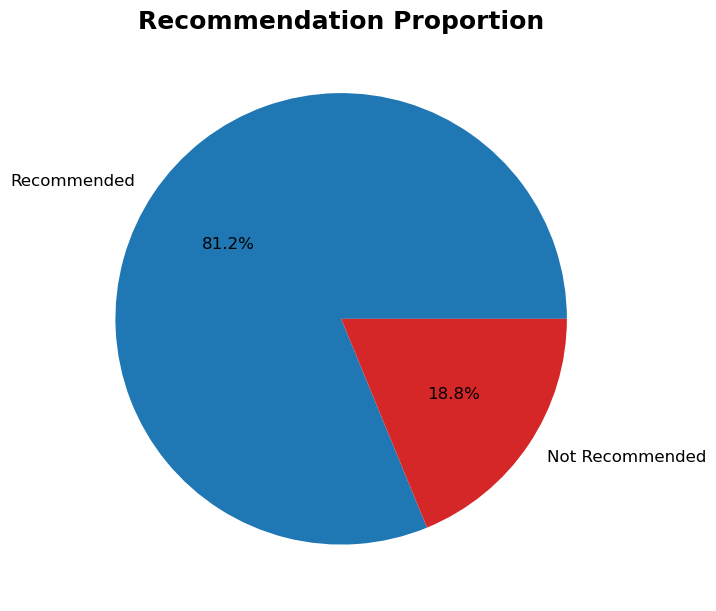

In [44]:
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

plt.pie(
    x=recommendation_proportion,
    labels=recommendation_proportion.index,
    autopct='%.1f%%',
    colors=['#1f77b4', '#d62728'],
    textprops={'fontsize': 12}
)

plt.title('Recommendation Proportion', fontweight='bold', fontsize=18)
plt.show()

##### <b>Most Played Games</b>

In [45]:
most_played_games = df_games_reviews_clean.groupby('game_name')['hours_played'].mean().reset_index()
most_played_games = most_played_games.sort_values(by='hours_played', ascending=False).head(10)

most_played_games

,game_name,hours_played
69,FINAL FANTASY XIV Online,4171.944311
34,Counter-Strike 2,2759.882073
193,Team Fortress 2,2595.629760
81,Garry's Mod,2235.975165
230,Warframe,2056.904691
16,Arma 3,1975.602136
3,ARK: Survival Evolved,1908.350200
46,Destiny 2,1869.504113
65,Europa Universalis IV,1835.957238
229,War Thunder,1633.882591


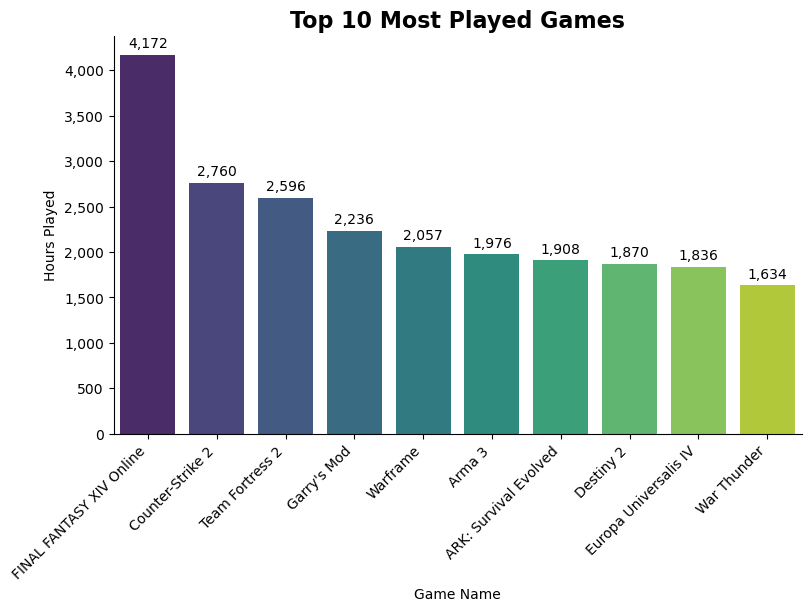

In [46]:
# Visualization

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

g = sns.barplot(
    most_played_games,
    x='game_name',
    y='hours_played',
    palette='viridis',
    hue='game_name',
    ax=ax
)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, loc: f"{int(x):,}"))

ax.tick_params(axis='x', rotation=45)

for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')

# Bar labels
for container in ax.containers:
    labels = [f'{val:,.0f}' for val in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

ax.set_title('Top 10 Most Played Games', fontweight='bold', fontsize=16)
ax.set_xlabel('Game Name')
ax.set_ylabel('Hours Played')

sns.despine()

plt.show()

##### <b>Top 10 Reviewed Genres</b>

In [47]:
top_10_reviewed_genres = df_genres_exploded.groupby('genres')['number_of_reviews_from_purchased_people'].sum().reset_index()
top_10_reviewed_genres = top_10_reviewed_genres.sort_values(by='number_of_reviews_from_purchased_people', ascending=False).head(10)

top_10_reviewed_genres

,genres,number_of_reviews_from_purchased_people
14,Action,43897553
196,Multiplayer,40568217
65,Co-op,34523056
124,First-Person,30359237
211,Online Co-Op,27852721
274,Singleplayer,27015747
269,Shooter,25132959
116,FPS,23571787
237,PvP,22674824
294,Strategy,21160774


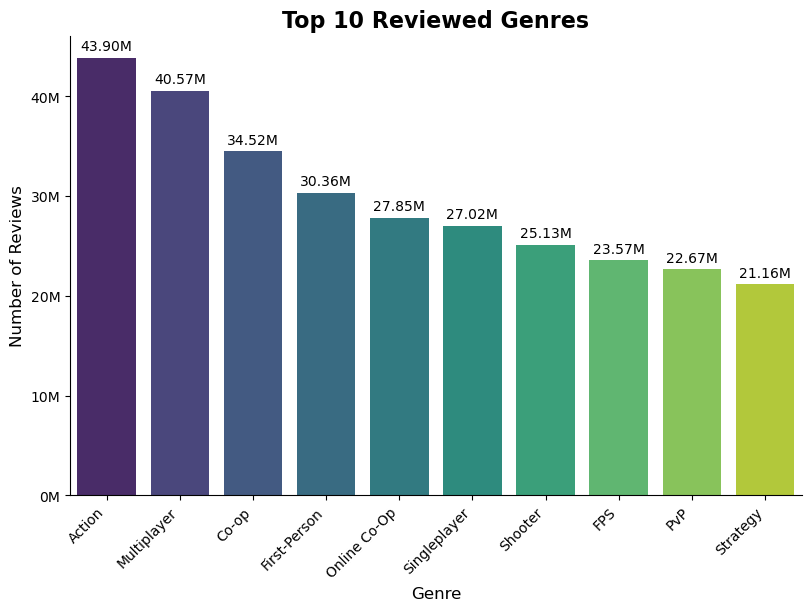

In [48]:
# Visualization

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

g = sns.barplot(
    top_10_reviewed_genres,
    x='genres',
    y='number_of_reviews_from_purchased_people',
    palette='viridis',
    hue='genres',
    ax=ax
)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, loc: f"{x/1000000:.0f}M"))

ax.tick_params(axis='x', rotation=45)

for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')

# Bar labels
for container in ax.containers:
    labels = [f'{val/1000000:.2f}M' for val in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

ax.set_title('Top 10 Reviewed Genres', fontweight='bold', fontsize=16)
ax.set_xlabel('Genre', fontsize=12)
ax.set_ylabel('Number of Reviews', fontsize=12)

sns.despine()

plt.show()

##### <b>Developer Analysis</b>

<b>Top Rated Developer</b>

In [49]:
top_rated_devs = df_dev_exploded.groupby('developer')['game_name'].nunique().reset_index()
top_rated_devs = top_rated_devs.sort_values(by='game_name', ascending=False).head(10)

top_rated_devs

,developer,game_name
121,Milestone S.r.l.,10
28,CREATIVE ASSEMBLY,8
26,"CAPCOM Co., Ltd.",6
211,Treyarch,6
227,Valve,6
231,Visual Concepts,6
63,Feral Interactive (Mac),6
62,Feral Interactive (Linux),5
139,Paradox Development Studio,5
88,Infinity Ward,4


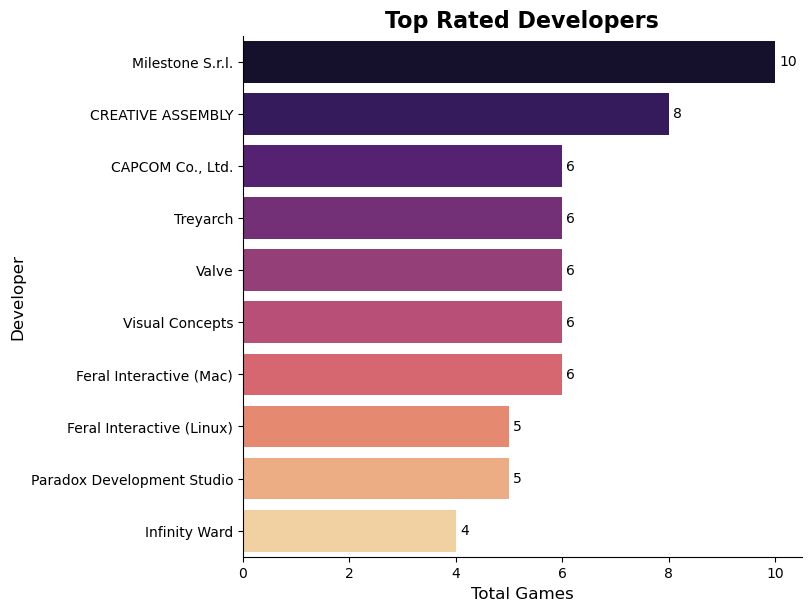

In [50]:
# Visualization

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

sns.barplot(
    top_rated_devs,
    x='game_name',
    y='developer',
    palette='magma',
    hue='developer',
    ax=ax,
)

# Bar labels
for container in ax.containers:
    labels = [f'{val:,.0f}' for val in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

ax.set_title('Top Rated Developers', fontweight='bold', fontsize=16)
ax.set_xlabel('Total Games', fontsize=12)
ax.set_ylabel('Developer', fontsize=12)

sns.despine()

plt.show()

<b>Best Performing Devs</b>

In [51]:
# Get games with only overwhelmingly positive reviews
overpos_devs = df_dev_exploded[df_dev_exploded['overall_player_rating'] == 'Overwhelmingly Positive']
overpos_devs.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,"[Mythology, Action RPG, Action, RPG, Souls-lik...",2024-08-19,Game Science,[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...
29,The Witcher 3: Wild Hunt,"You are Geralt of Rivia, mercenary monster sla...",THE MOST AWARDED GAME OF A GENERATIONNOW ENHAN...,"[Open World, RPG, Story Rich, Atmospheric, Mat...",2015-05-18,CD PROJEKT RED,[CD PROJEKT RED],Overwhelmingly Positive,726659,229117,https://store.steampowered.com/app/292030/The_...
33,Noita,Noita is a magical action roguelite set in a w...,Noita is a magical action roguelite set in a w...,"[Physics, Difficult, Roguelike, Pixel Graphics...",2020-10-15,Nolla Games,[Nolla Games],Overwhelmingly Positive,63810,42592,https://store.steampowered.com/app/881100/Noit...
38,Wallpaper Engine,Use stunning live wallpapers on your desktop. ...,About This Software\n\t\t\t\t\t\t\tWallpaper E...,"[Mature, Utilities, Software, Anime, Design & ...",2018-11-01,Wallpaper Engine Team,[Wallpaper Engine Team],Overwhelmingly Positive,760648,210537,https://store.steampowered.com/app/431960/Wall...
46,Terraria,"Dig, fight, explore, build! Nothing is impossi...","Dig, Fight, Explore, Build: The very world is...","[Open World Survival Craft, Sandbox, Survival,...",2011-05-16,Re-Logic,[Re-Logic],Overwhelmingly Positive,1061260,657354,https://store.steampowered.com/app/105600/Terr...


In [52]:
best_perform_devs = overpos_devs.groupby('developer')['overall_player_rating'].count().reset_index()
best_perform_devs = best_perform_devs.sort_values(by='overall_player_rating', ascending=False).head(10)
best_perform_devs

,developer,overall_player_rating
78,Valve,3
0,ATLUS,2
3,Aspyr (Mac),2
7,"CAPCOM Co., Ltd.",2
23,Feral Interactive (Mac),2
2,Aspyr (Linux),2
37,Larian Studios,2
64,SCS Software,2
8,CD PROJEKT RED,1
9,CREATIVE ASSEMBLY,1


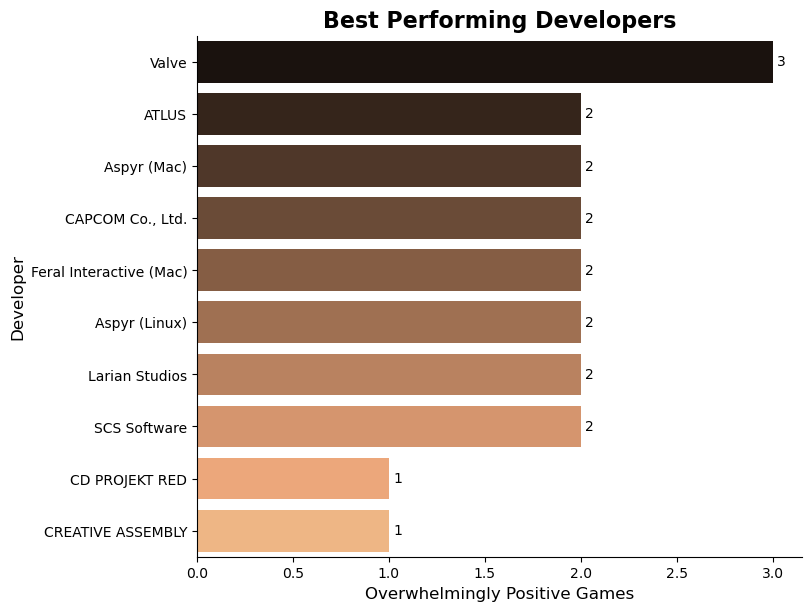

In [53]:
# Visualization

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

sns.barplot(
    best_perform_devs,
    x='overall_player_rating',
    y='developer',
    palette='copper',
    hue='developer',
    ax=ax,
)

# Bar labels
for container in ax.containers:
    labels = [f'{val:,.0f}' for val in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

ax.set_title('Best Performing Developers', fontweight='bold', fontsize=16)
ax.set_xlabel('Overwhelmingly Positive Games', fontsize=12)
ax.set_ylabel('Developer', fontsize=12)

sns.despine()

plt.show()

##### <b>Correlation between Hours Played and Recommendation</b>

In [54]:
df_games_reviews_clean['hours_played'].describe()

count    991649.000000
mean        339.226398
std        1209.408206
min           0.000000
25%          18.900000
50%          59.600000
75%         208.400000
max      107075.100000
Name: hours_played, dtype: float64

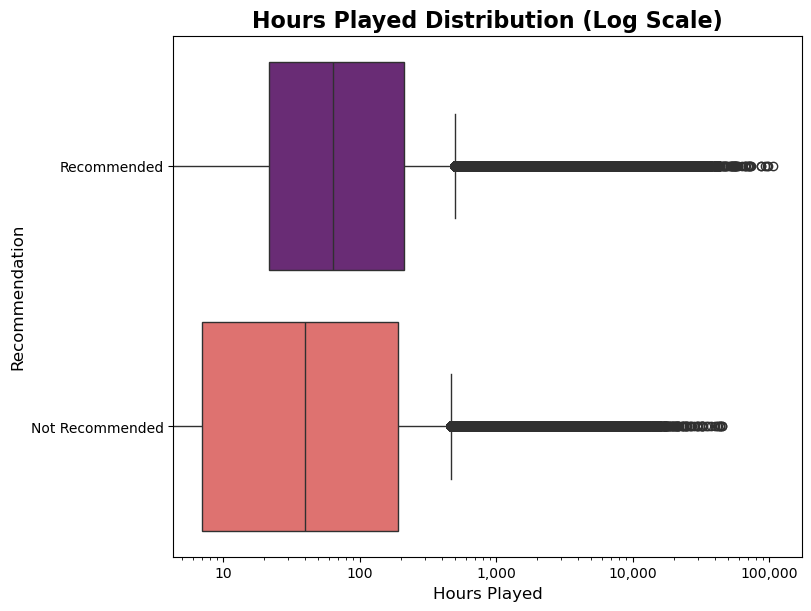

In [55]:
# Visualization
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

sns.boxplot(
    df_games_reviews_clean,
    x='hours_played',
    y='recommendation',
    palette='magma',
    hue='recommendation',
    legend=False,
)

ax.set_title('Hours Played Distribution (Log Scale)', fontsize=16, fontweight='bold')
ax.set_xlabel('Hours Played', fontsize=12)
ax.set_ylabel('Recommendation', fontsize=12)

ax.set_xscale('log')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))

plt.show()

- <b>Median Difference</b>: Recommended's median is more to the right (~60-70 hours) compared to Not Recommended's (~40 hours), this indicates that player that enjoys the game have a longer playtime
- <b>Early Bounce</b>: Q1 in Not Recommended is more to the left until under 10 hours. A lot of negative reviews come from players that are disappointed in early game (e.g. bugs, crashes, and refunds)
- <b>Extreme Outlier in Both Sides</b>: Both positive and negative reviews have hardcore players that have tons of hours played. This shows that even veteran players can leave a negative reviews such as a bad experience due to an update.


In [56]:
df_games_reviews_clean.groupby('recommendation').agg({
    'hours_played': ['mean', 'median'],
})

hours_played       
                        mean median
recommendation                     
Not Recommended   316.266324   39.7
Recommended       344.538941   63.7

In [57]:
# Map recommendation column
rec_binary = df_games_reviews_clean['recommendation'].map({'Not Recommended': 0, 'Recommended': 1})

# Correlation score
corr_score = df_games_reviews_clean['hours_played'].corr(other=rec_binary, method='spearman')
corr_score

np.float64(0.1102951540518377)

A weak positive correlation at 0.1103 confirms that in general, the higher the hours played, the higher chance that the player leave a positive review (Recommended). However, because the value is around 0.11 (which is far from 1.0), it's considered a weak correlation.


##### <b>Genre Release Trend</b>

In [58]:
df_genres_exploded['release_year'] = df_genres_exploded['release_date'].dt.year
df_genres_exploded['release_year'].describe()

count    5507.000000
mean     2019.440167
std         4.290636
min      2004.000000
25%      2017.000000
50%      2020.000000
75%      2023.000000
max      2024.000000
Name: release_year, dtype: float64

In [59]:
top_5_genre_released = df_genres_exploded[df_genres_exploded['genres'].isin(top_10_reviewed_genres['genres'].head(5))]
top_5_genre_released.head()

,game_name,short_description,long_description,genres,release_date,developer,publisher,overall_player_rating,number_of_reviews_from_purchased_people,number_of_english_reviews,link,release_year
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...,Black Myth: Wukong is an action RPG rooted in ...,Action,2024-08-19,[Game Science],[Game Science],Overwhelmingly Positive,654820,51931,https://store.steampowered.com/app/2358720/Bla...,2024
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",Multiplayer,2012-08-21,[Valve],[Valve],Very Positive,8313603,2258990,https://store.steampowered.com/app/730/Counter...,2012
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",Action,2012-08-21,[Valve],[Valve],Very Positive,8313603,2258990,https://store.steampowered.com/app/730/Counter...,2012
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",First-Person,2012-08-21,[Valve],[Valve],Very Positive,8313603,2258990,https://store.steampowered.com/app/730/Counter...,2012
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",Online Co-Op,2012-08-21,[Valve],[Valve],Very Positive,8313603,2258990,https://store.steampowered.com/app/730/Counter...,2012


In [60]:
top_5_genre_released_year = top_5_genre_released.groupby(['release_year', 'genres']).agg({
    'game_name': 'nunique',
}).reset_index()

top_5_genre_released_year

,release_year,genres,game_name
0,2004,Action,1
1,2004,First-Person,1
2,2004,Multiplayer,1
3,2006,Action,3
4,2006,Co-op,2
...,...,...,...
87,2024,Action,24
88,2024,Co-op,21
89,2024,First-Person,14
90,2024,Multiplayer,34


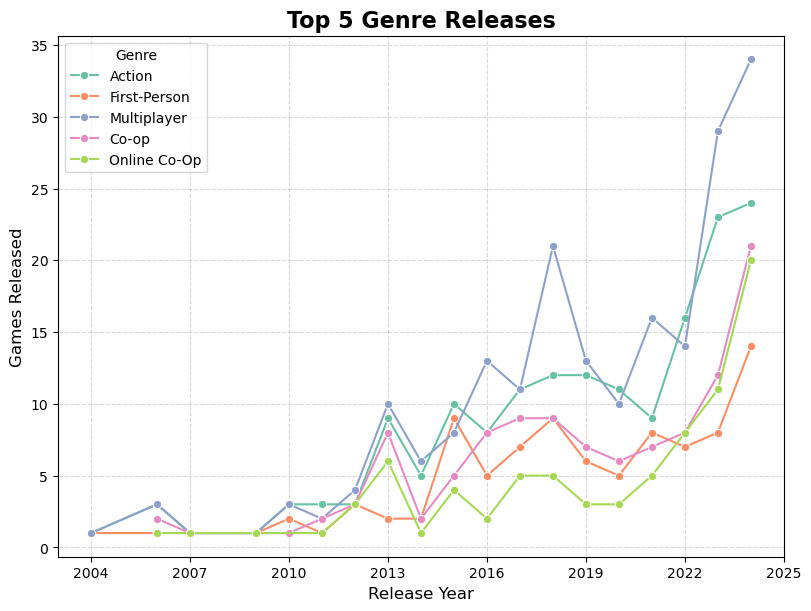

In [61]:
# Visualization
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

sns.lineplot(
    top_5_genre_released_year,
    x='release_year',
    y='game_name',
    hue='genres',
    palette='Set2',
    ax=ax,
    marker='o',
)

ax.set_title('Top 5 Genre Releases', fontweight='bold', fontsize=16)
ax.set_xlabel('Release Year', fontsize=12)
ax.set_ylabel('Games Released', fontsize=12)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.grid(True, linestyle='--', alpha=.5)
ax.legend(title='Genre')

plt.show()

##### <b>Engagement Ratio</b>

In [62]:
agg_df = df_games_reviews_clean.groupby('game_name').agg(
    mean_hours=('hours_played', 'mean'),
    median_hours=('hours_played', 'median'),
    sample_count=('review', 'count')
).reset_index()

engage_ratio = agg_df[agg_df['sample_count'] >= 30]
engage_ratio

,game_name,mean_hours,median_hours,sample_count
0,69 Balls,31.705000,1.35,120
1,7 Days to Die,938.414810,369.00,5010
2,ARK: Survival Ascended,312.439899,96.10,4940
3,ARK: Survival Evolved,1908.350200,658.70,5010
4,Age of Empires II (Retired),341.793214,104.30,5010
...,...,...,...,...
237,Yu-Gi-Oh! Master Duel,312.517303,108.90,4999
238,eFootball™,167.311756,12.70,5010
239,iRacing,248.356620,52.95,2598
240,shapez 2,43.878289,27.90,4712


In [63]:
df_unique_reviews_per_game = df_genres_exploded[['game_name', 'number_of_reviews_from_purchased_people']].drop_duplicates('game_name')

df_engagement = pd.merge(
    engage_ratio, 
    df_unique_reviews_per_game, 
    on='game_name', 
    how='inner'
)

df_engagement

,game_name,mean_hours,median_hours,sample_count,number_of_reviews_from_purchased_people
0,69 Balls,31.705000,1.35,120,143
1,7 Days to Die,938.414810,369.00,5010,231932
2,ARK: Survival Ascended,312.439899,96.10,4940,54833
3,ARK: Survival Evolved,1908.350200,658.70,5010,527988
4,Age of Empires II (Retired),341.793214,104.30,5010,82338
...,...,...,...,...,...
222,Yu-Gi-Oh! Master Duel,312.517303,108.90,4999,76889
223,eFootball™,167.311756,12.70,5010,80277
224,iRacing,248.356620,52.95,2598,2707
225,shapez 2,43.878289,27.90,4712,6553


C:\Users\Rio\AppData\Local\Temp\ipykernel_17648\1408097878.py:22: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


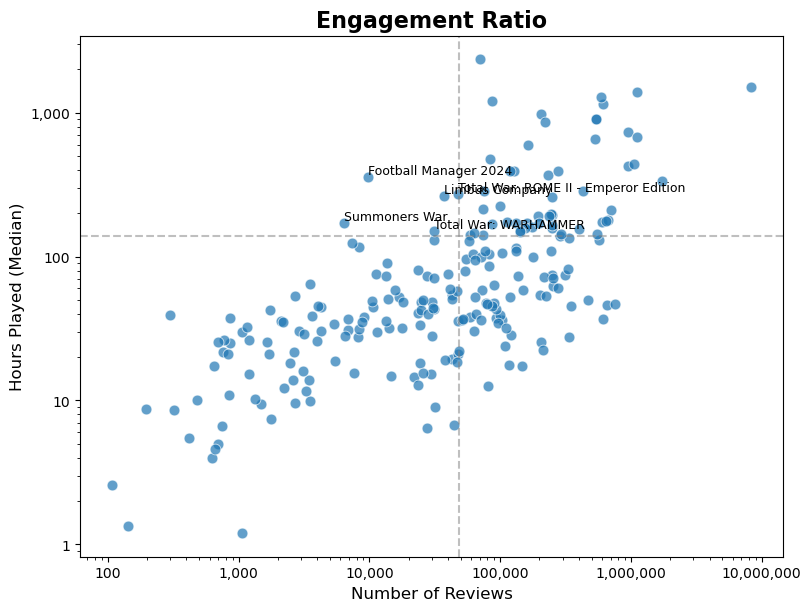

In [64]:
# Visualization
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

# Make quadrant lines
middle_line_x = df_engagement['number_of_reviews_from_purchased_people'].median()
middle_line_y = df_engagement['median_hours'].quantile(.75)

df_engagement['is_cult_classic'] = (
    (df_engagement['number_of_reviews_from_purchased_people'] < middle_line_x) & 
    (df_engagement['median_hours'] > middle_line_y)
)

top_cult_games = (
    df_engagement[df_engagement['is_cult_classic']]
    .sort_values(by='median_hours', ascending=False)
    .head(10)
)

plt.axvline(middle_line_x, color='grey', linestyle='--', alpha=0.5)
plt.axhline(middle_line_y, color='grey', linestyle='--', alpha=0.5)

sns.scatterplot(
    df_engagement,
    x='number_of_reviews_from_purchased_people',
    y='median_hours',
    alpha=0.7,
    s=60,
    palette={False: '#95a5a6', True: '#e74c3c'},
    ax=ax,
    legend=False,
)

ax.set_xscale('log')
ax.set_yscale('log')

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y:,.0f}"))

for idx, row in top_cult_games.iterrows():
    ax.text(
        x=row['number_of_reviews_from_purchased_people'], 
        y=row['median_hours'] * 1.05,
        s=row['game_name'], 
        fontsize=9
    )

ax.set_title('Engagement Ratio', fontweight='bold', fontsize=16)
ax.set_xlabel('Number of Reviews', fontsize=12)
ax.set_ylabel('Hours Played (Median)', fontsize=12)

plt.show()

#### <b>Review Text Analysis</b>

<b>Review Length vs Recommendation</b>

In [65]:
df_games_reviews_clean['review_length'] = df_games_reviews_clean['review'].astype(str).str.len()
df_games_reviews_clean['review_length'].head()

0     616
1    1338
2     774
3      86
4      97
Name: review_length, dtype: int64

In [66]:
df_games_reviews_clean.groupby('recommendation').agg({
    'review_length': ['mean', 'median']
}).reset_index()

recommendation review_length       
                            mean median
0  Not Recommended    586.220587  229.0
1      Recommended    340.787962   91.0

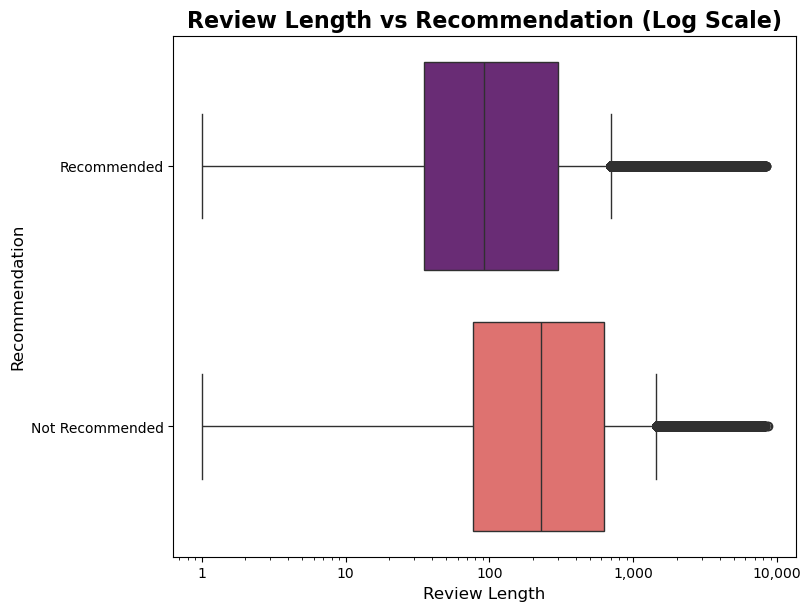

In [67]:
# Visualization
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

sns.boxplot(
    df_games_reviews_clean,
    x='review_length',
    y='recommendation',
    palette='magma',
    hue='recommendation',
    legend=False,
)

ax.set_title('Review Length vs Recommendation (Log Scale)', fontsize=16, fontweight='bold')
ax.set_xlabel('Review Length', fontsize=12)
ax.set_ylabel('Recommendation', fontsize=12)

ax.set_xscale('log')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))

plt.show()

- Players who don't recommend a game tends to give a longer review compared to players who recommend. The review length median for Not Recommended is 229 characters, which is around 2,5 times more than Recommended with 91 characters. Their mean is also very distant (586,2 compared to 340,8).
- Shift of Distribution: The box plot and its value (Q1, median, Q3) for Not Recommended reviews shift way to the right compared to Recommended reviews.
- Usually, players who give a positive review tends to leave a brief compliment such as "good game", "fun", or "10/10". In contrast, players who don't recommend usually writes an elaboration of why they are unsatisfied with the game. These disappointed players usually gives detailed explanation such as their experience with bugs, crash, gameplay mechanics, or why the game is not worth the price.

In [68]:
# Stratified sampling for each recommendation
pos_review_sample = df_games_reviews_clean[df_games_reviews_clean['recommendation'] == 'Recommended']['review'].sample(n=50000, random_state=42)
neg_review_sample = df_games_reviews_clean[df_games_reviews_clean['recommendation'] == 'Not Recommended']['review'].sample(n=50000, random_state=42)

In [69]:
def clean_text(series):
    return (
        series.astype(str)
        .str.lower()
        # Ignore automatic phrases
        .str.replace(r'early access review|product received for free|product refunded', '', regex=True)
        .str.replace(r'http\S+|www\S+', '', regex=True)      # Remove URL
        .str.replace(r'[^a-z\s]', ' ', regex=True)              # Keep alphabets and spaces
        .str.replace(r'\s+', ' ', regex=True)                   # Fix double spaces
        .str.replace(r'\b(\w+)(?:\s+\1)+\b', r'\1', regex=True) # Trim repeated words (e.g.: "crash crash" -> "crash")
        .str.strip()
    )

pos_review_clean = clean_text(pos_review_sample)
neg_review_clean = clean_text(neg_review_sample)

In [70]:
custom_stops = list(ENGLISH_STOP_WORDS) + ['game', 'games', 'play', 'playing', 'played', 'steam']

def get_top_ngrams(corpus, ngram_range=(2, 3), top_n=15):
    vec = CountVectorizer(
        ngram_range=ngram_range, 
        stop_words=custom_stops, 
        max_features=5000
    )
    bag_of_words = vec.fit_transform(corpus)
    
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    
    return pd.DataFrame(words_freq[:top_n], columns=['phrase', 'count'])

top_pos_phrases = get_top_ngrams(pos_review_clean)
top_neg_phrases = get_top_ngrams(neg_review_clean)

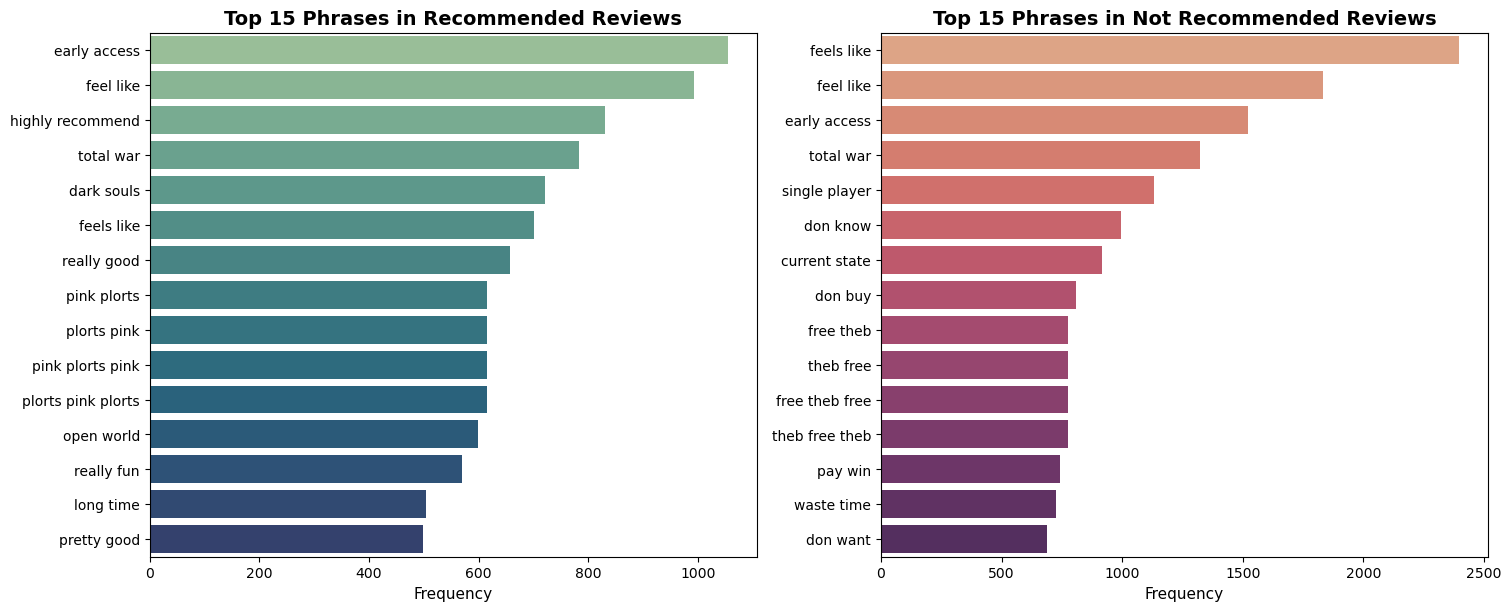

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')

# Left: Positive Review
sns.barplot(
    data=top_pos_phrases, x='count', y='phrase', 
    palette='crest', hue='phrase', legend=False, ax=axes[0]
)
axes[0].set_title('Top 15 Phrases in Recommended Reviews', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Frequency', fontsize=11)
axes[0].set_ylabel('')

# Right: Negative Review
sns.barplot(
    data=top_neg_phrases, x='count', y='phrase', 
    palette='flare', hue='phrase', legend=False, ax=axes[1]
)
axes[1].set_title('Top 15 Phrases in Not Recommended Reviews', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frequency', fontsize=11)
axes[1].set_ylabel('')

plt.show()

<b>Insights from Positive Reviews</b>

Phrases like "highly recommend", "really good", "really fun", and "pretty good" indicates that players who recommend a game gave positive feedback to prospective buyers.

<b>Insights from Negative Reviews</b>
1. <b>Games in Unfinished State</b>: The high frequency of phrases like "current state" and "early access" indicate that players are disappointed with the state of the game.
2. <b>Monetization</b>: Microtransactions that are executed poorly triggers negative reviews.
3. <b>Franchise-Specific Sentiment</b>: The phrase "total war" (especially in negative reviews) reflect a review bombing phenomenon.

### <b>End of Project</b>